# CSCI1409 Bonus Project — African Wildlife Object Detection (YOLO11n)

Fine-tunes a COCO-pretrained **YOLO11n** on the **African Wildlife** dataset (buffalo, elephant, rhino, zebra),
runs one controlled experiment (**image size 640 → 320**), evaluates the selected model on the held-out test set
and analyses failure cases.

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
Total time on a free T4 is roughly 30–40 minutes. Everything starts from a fresh runtime.

## 0. Environment

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "No GPU - training will be very slow"

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [16]:
REPO_URL = "https://github.com/Alikhan7RK/csci1409-object-detection.git"

import os
if not os.path.exists("/content/csci1409-object-detection"):
    !git clone -q {REPO_URL} /content/csci1409-object-detection
%cd /content/csci1409-object-detection

/content/csci1409-object-detection


In [3]:
!pip install -q -r requirements.txt
import ultralytics, torch, platform
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| CUDA", torch.version.cuda,
      "| python", platform.python_version())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.215 | torch 2.14.1+cu130 | CUDA 13.0 | python 3.13.16
GPU: Tesla T4


## 1. Dataset
Download the official split, then inspect it: images/objects per split, label sanity checks and a
near-duplicate search (perceptual hashes).

In [4]:
!python scripts/prepare_data.py
!python scripts/data_report.py --data datasets/african-wildlife.yaml

train: 1052 images
val  : 225 images
test : 227 images
Wrote /content/csci1409-object-detection/datasets/african-wildlife.yaml
| Split | Images | buffalo | elephant | rhino | zebra | Total objects |
|---|---|---|---|---|---|---|
| train | 1052 | 399 | 558 | 399 | 575 | 1931 |
| val | 225 | 89 | 91 | 85 | 114 | 379 |
| test | 227 | 66 | 99 | 75 | 135 | 375 |
| **total** | **1504** | **554** | **748** | **559** | **824** | **2685** |
{
  "label_issue_counts": {},
  "near_duplicate_pairs": 72,
  "cross_split_near_duplicate_pairs": 34,
  "phash_threshold": 10,
  "dhash_threshold": 10,
  "median_box_area_fraction": {
    "buffalo": 0.31966205000000003,
    "zebra": 0.14887158236,
    "elephant": 0.17278163124999998,
    "rhino": 0.297282540456
  }
}
Saved report to /content/csci1409-object-detection/results/data/african-wildlife


The official split contains **the same photographs in train and val/test** (cross-split duplicates → data
leakage). `make_clean_split.py` groups duplicates and moves each cross-split group to *train*
(deterministic rule, no randomness). We then re-run the report to confirm **0 cross-split duplicates**.

In [5]:
!python scripts/make_clean_split.py
!python scripts/data_report.py --data datasets/african-wildlife-clean.yaml

Moved 32 images to train to remove cross-split duplicates
New split sizes: {'train': 1084, 'val': 215, 'test': 205}
Wrote /content/csci1409-object-detection/datasets/african-wildlife-clean.yaml
| Split | Images | buffalo | elephant | rhino | zebra | Total objects |
|---|---|---|---|---|---|---|
| train | 1084 | 417 | 565 | 413 | 587 | 1982 |
| val | 215 | 86 | 87 | 79 | 111 | 363 |
| test | 205 | 51 | 96 | 67 | 126 | 340 |
| **total** | **1504** | **554** | **748** | **559** | **824** | **2685** |
{
  "label_issue_counts": {},
  "near_duplicate_pairs": 72,
  "cross_split_near_duplicate_pairs": 0,
  "phash_threshold": 10,
  "dhash_threshold": 10,
  "median_box_area_fraction": {
    "buffalo": 0.31966205000000003,
    "zebra": 0.14887158236,
    "elephant": 0.17278163124999998,
    "rhino": 0.297282540456
  }
}
Saved report to /content/csci1409-object-detection/results/data/african-wildlife-clean


| Split | Images | buffalo | elephant | rhino | zebra | Total objects |
|---|---|---|---|---|---|---|
| train | 1084 | 417 | 565 | 413 | 587 | 1982 |
| val | 215 | 86 | 87 | 79 | 111 | 363 |
| test | 205 | 51 | 96 | 67 | 126 | 340 |
| **total** | **1504** | **554** | **748** | **559** | **824** | **2685** |


,split_a,image_a,split_b,image_b,phash_distance,dhash_distance,type,class_labels
0,train,1 (123).jpg,train,1 (313).jpg,0,1,same split,same
1,train,1 (124).jpg,val,1 (122).jpg,0,0,CROSS-SPLIT,same
2,train,1 (141).jpg,train,1 (226).jpg,0,2,same split,same
3,train,1 (151).jpg,test,1 (103).jpg,0,0,CROSS-SPLIT,same
4,train,1 (184).jpg,train,1 (238).jpg,0,1,same split,same
5,train,1 (229).jpg,val,1 (223).jpg,0,0,CROSS-SPLIT,same
6,train,1 (236).jpg,train,1 (36).jpg,0,2,same split,same
7,train,1 (237).jpg,test,1 (365).jpg,0,2,CROSS-SPLIT,same
8,train,1 (241).jpg,train,1 (332).jpg,0,1,same split,same
9,train,1 (306).jpg,train,1 (8).jpg,0,0,same split,same


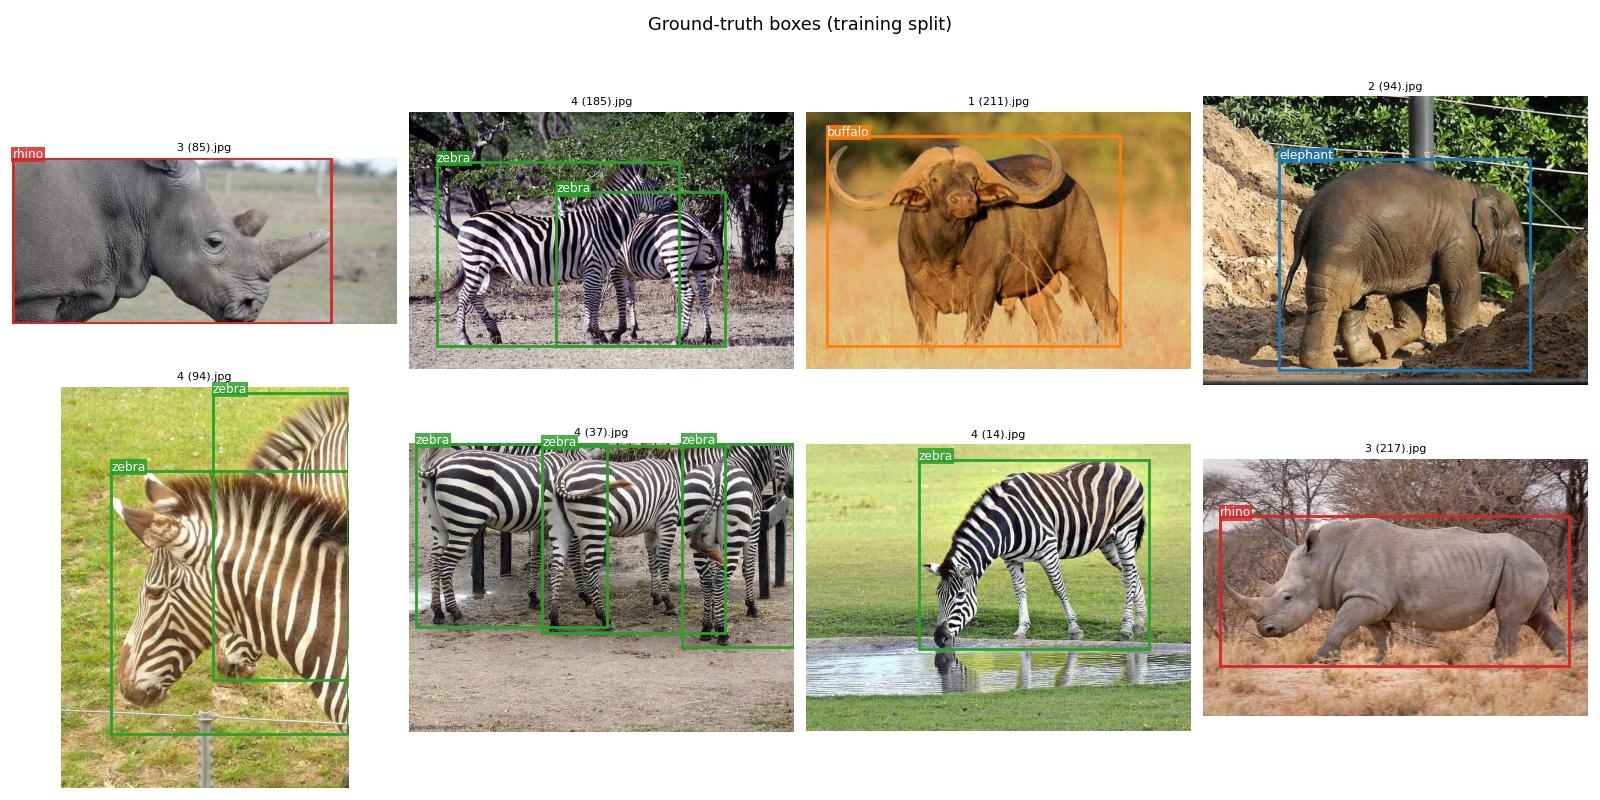

In [6]:
from IPython.display import Image, Markdown, display
import json, pandas as pd
display(Markdown(open("results/data/african-wildlife-clean/stats.md").read()))
display(pd.read_csv("results/data/african-wildlife/duplicates.csv").head(10))
display(Image("results/data/african-wildlife-clean/gt_samples.jpg", width=1100))

### Missing / wrong label check
A COCO-pretrained YOLO11m already knows *elephant* and *zebra*. Confident COCO detections with no matching
ground-truth box are **candidates** for missing labels (they must be verified by eye).

123 candidate boxes: {'possible_missing_label': 122, 'possible_wrong_class': 1}
Saved /content/csci1409-object-detection/results/data/label_check_candidates.csv


,split,image,flag,coco_class,coco_conf,best_iou_with_gt_same_class,detail,x1,y1,x2,y2
0,train,1 (300).jpg,possible_missing_label,zebra,0.946,0.167,max IoU with any GT box 0.17,587,176,959,533
1,train,2 (360).jpg,possible_missing_label,elephant,0.918,0.169,max IoU with any GT box 0.17,5,929,211,1117
2,train,4 (256).jpg,possible_missing_label,zebra,0.917,0.018,max IoU with any GT box 0.02,1127,360,1299,559
3,test,2 (290).jpg,possible_missing_label,zebra,0.897,0.000,max IoU with any GT box 0.00,552,230,616,301
4,train,3 (374).jpg,possible_wrong_class,elephant,0.888,0.000,GT says zebra,211,241,466,419
5,train,4 (229).jpg,possible_missing_label,zebra,0.880,0.081,max IoU with any GT box 0.08,704,579,1109,902
6,train,2 (116).jpg,possible_missing_label,elephant,0.879,0.000,max IoU with any GT box 0.00,0,1,62,307
7,train,2 (33).jpg,possible_missing_label,elephant,0.876,0.000,max IoU with any GT box 0.00,532,111,640,281
8,train,4 (334).jpg,possible_missing_label,zebra,0.873,0.096,max IoU with any GT box 0.10,1799,381,1919,499
9,train,2 (5).jpg,possible_missing_label,elephant,0.866,0.163,max IoU with any GT box 0.16,163,106,274,331


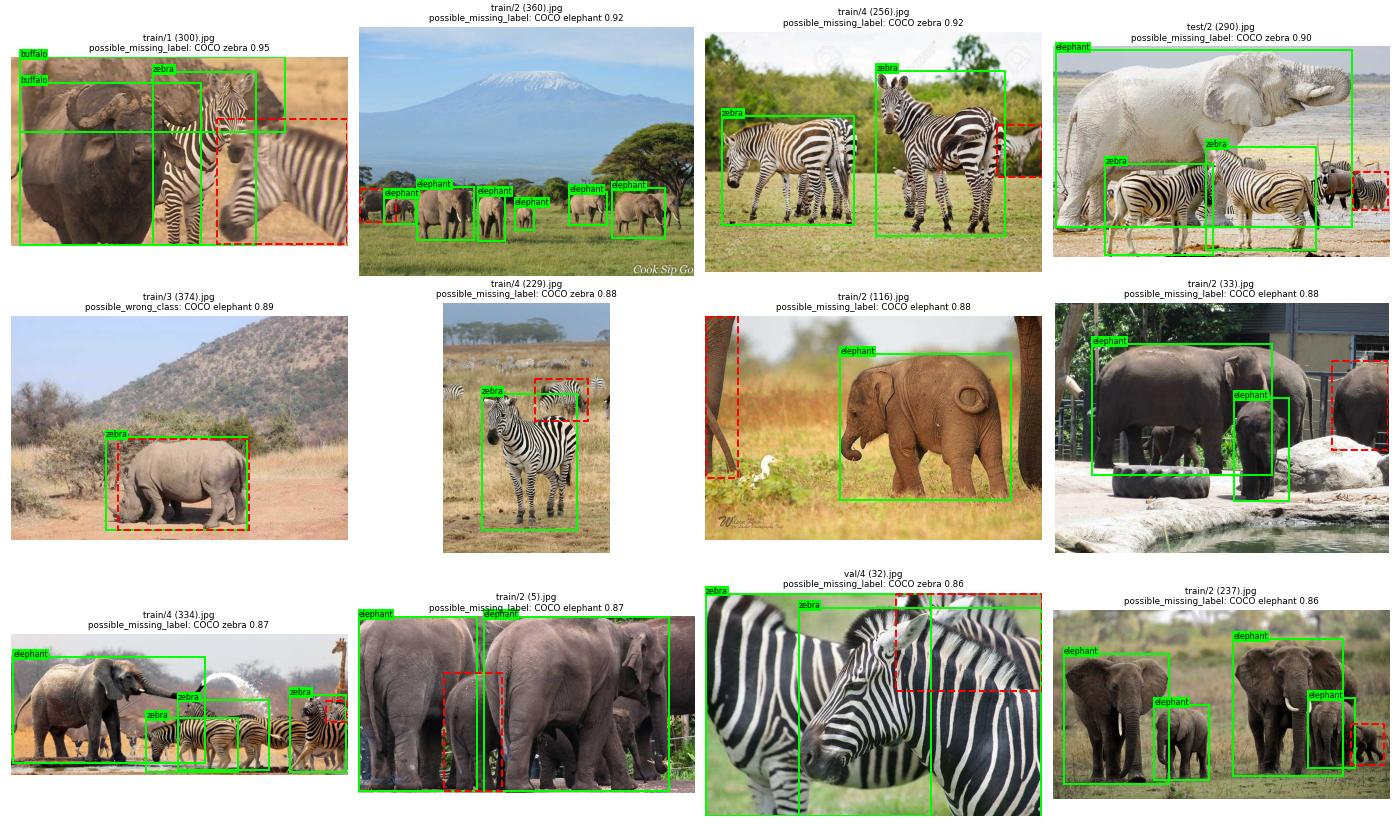

In [7]:
!python scripts/check_missing_labels.py --data datasets/african-wildlife-clean.yaml
display(pd.read_csv("results/data/label_check_candidates.csv").head(15))
display(Image("results/data/label_check_candidates.jpg", width=1100))

## 2. Run A — baseline (imgsz 640)
Settings are in `configs/baseline.yaml` (YOLO11n COCO weights, 40 epochs, batch 16, SGD lr0=0.01, seed 42).

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/csci1409-object-detection/datasets/african-wildlife-clean.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

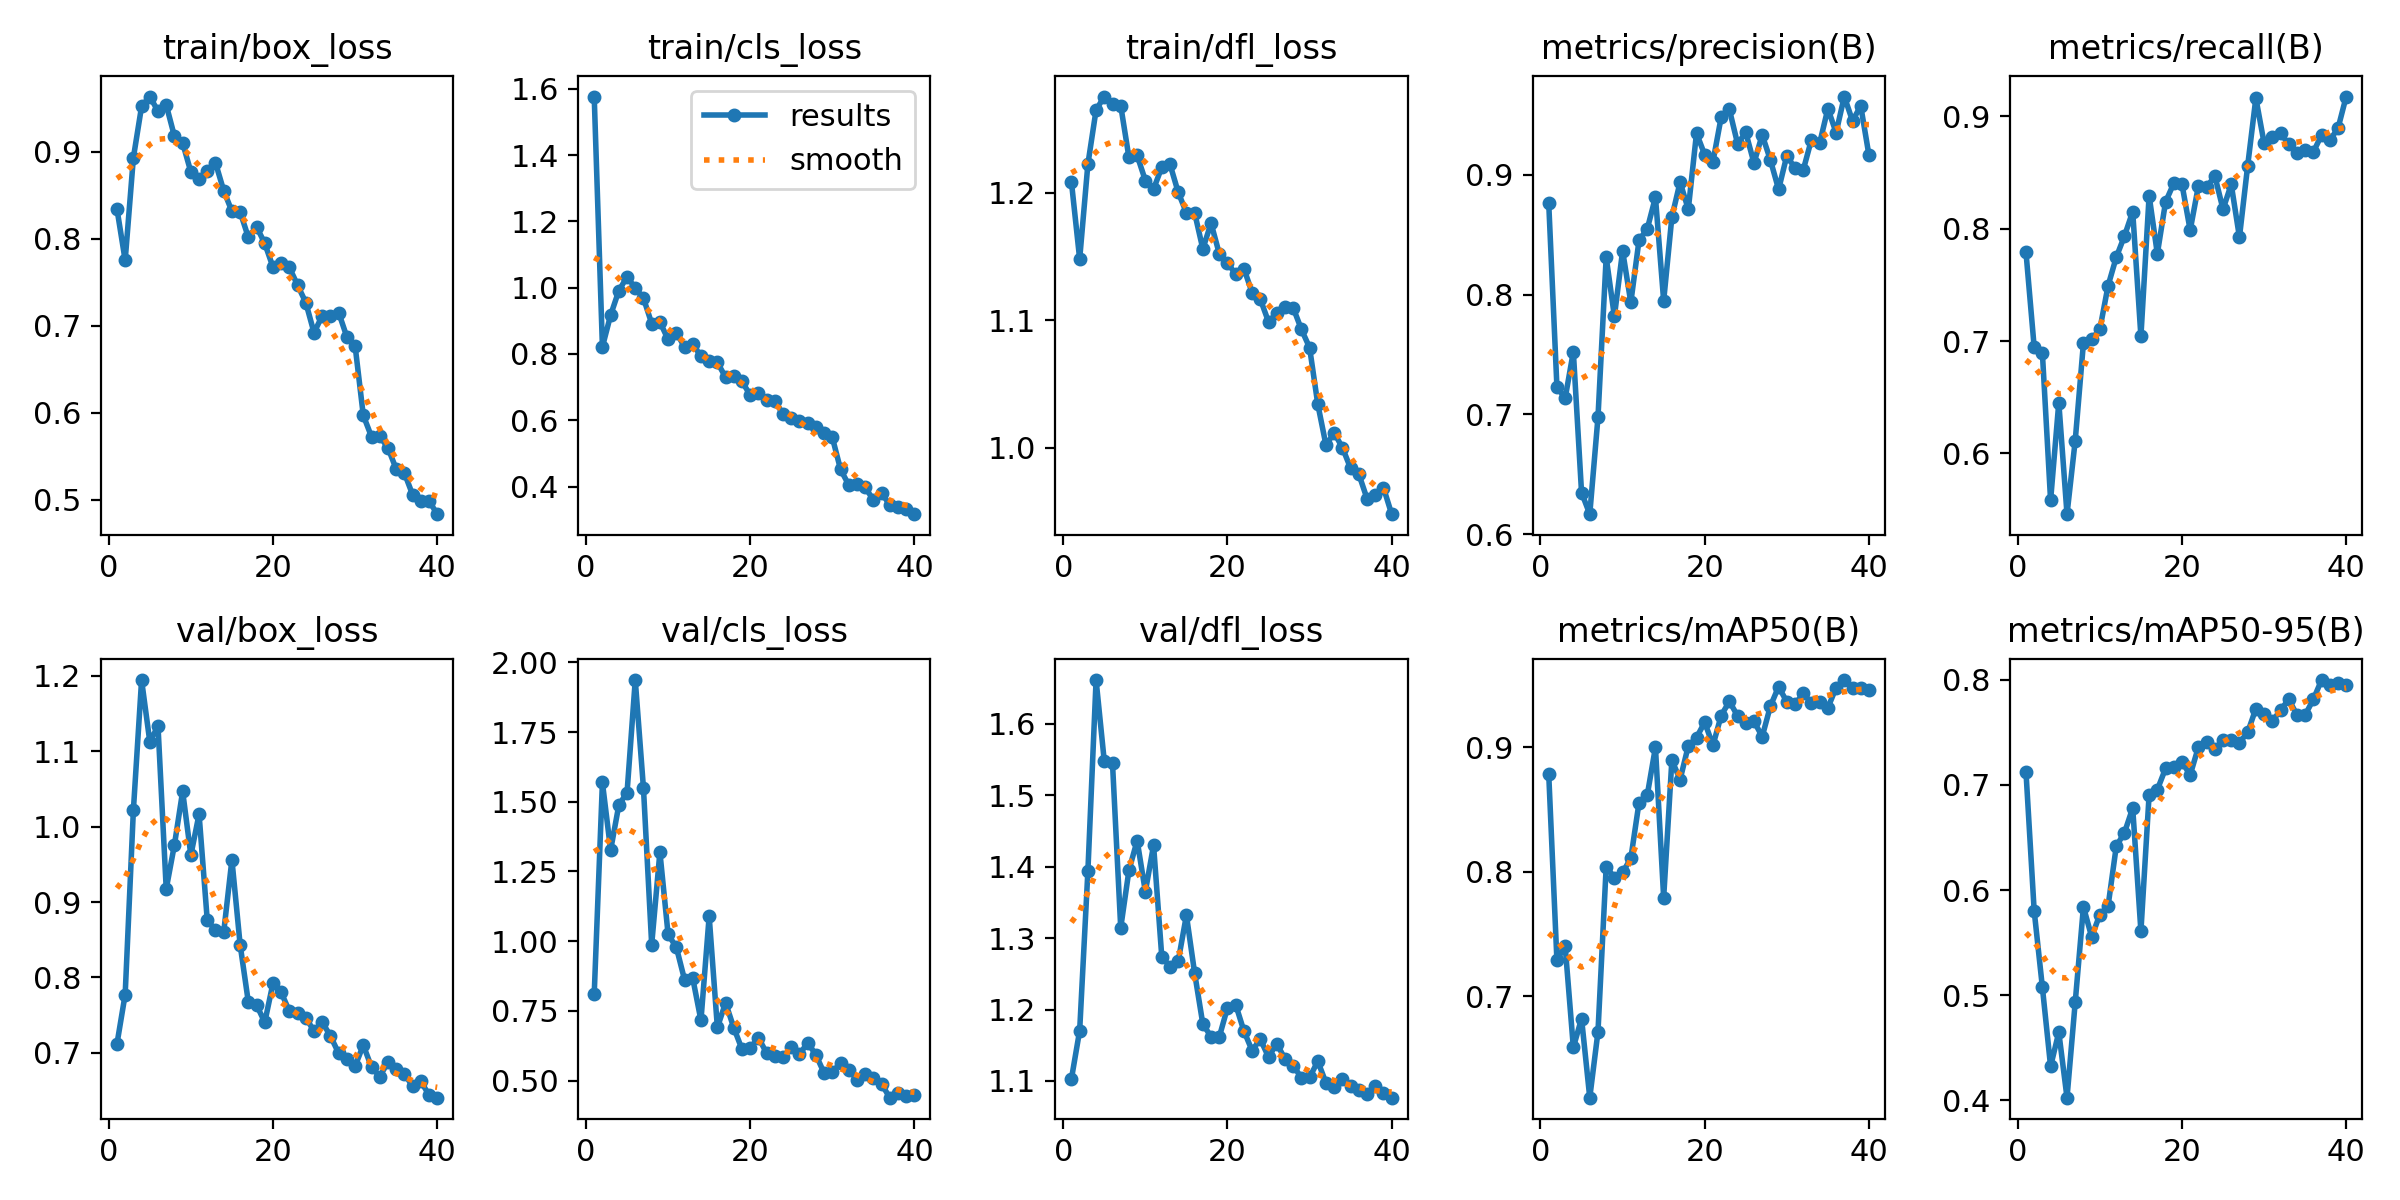

In [8]:
!python scripts/train.py --config configs/baseline.yaml
display(Image("runs/baseline/results.png", width=1100))

## 3. Run B — controlled experiment (imgsz 320)
**Hypothesis (written before training):** the animals are large in most images (median box covers 15–32 % of the
image), so halving the input resolution to 320 should lower validation mAP@0.50 only slightly (≤ 3 points),
while making training noticeably faster. Any loss should come mostly from small / distant animals and herds.

Only `imgsz` changes; data split, initial checkpoint, seed, epochs, batch and learning rate are identical.

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/csci1409-object-detection/datasets/african-wildlife-clean.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

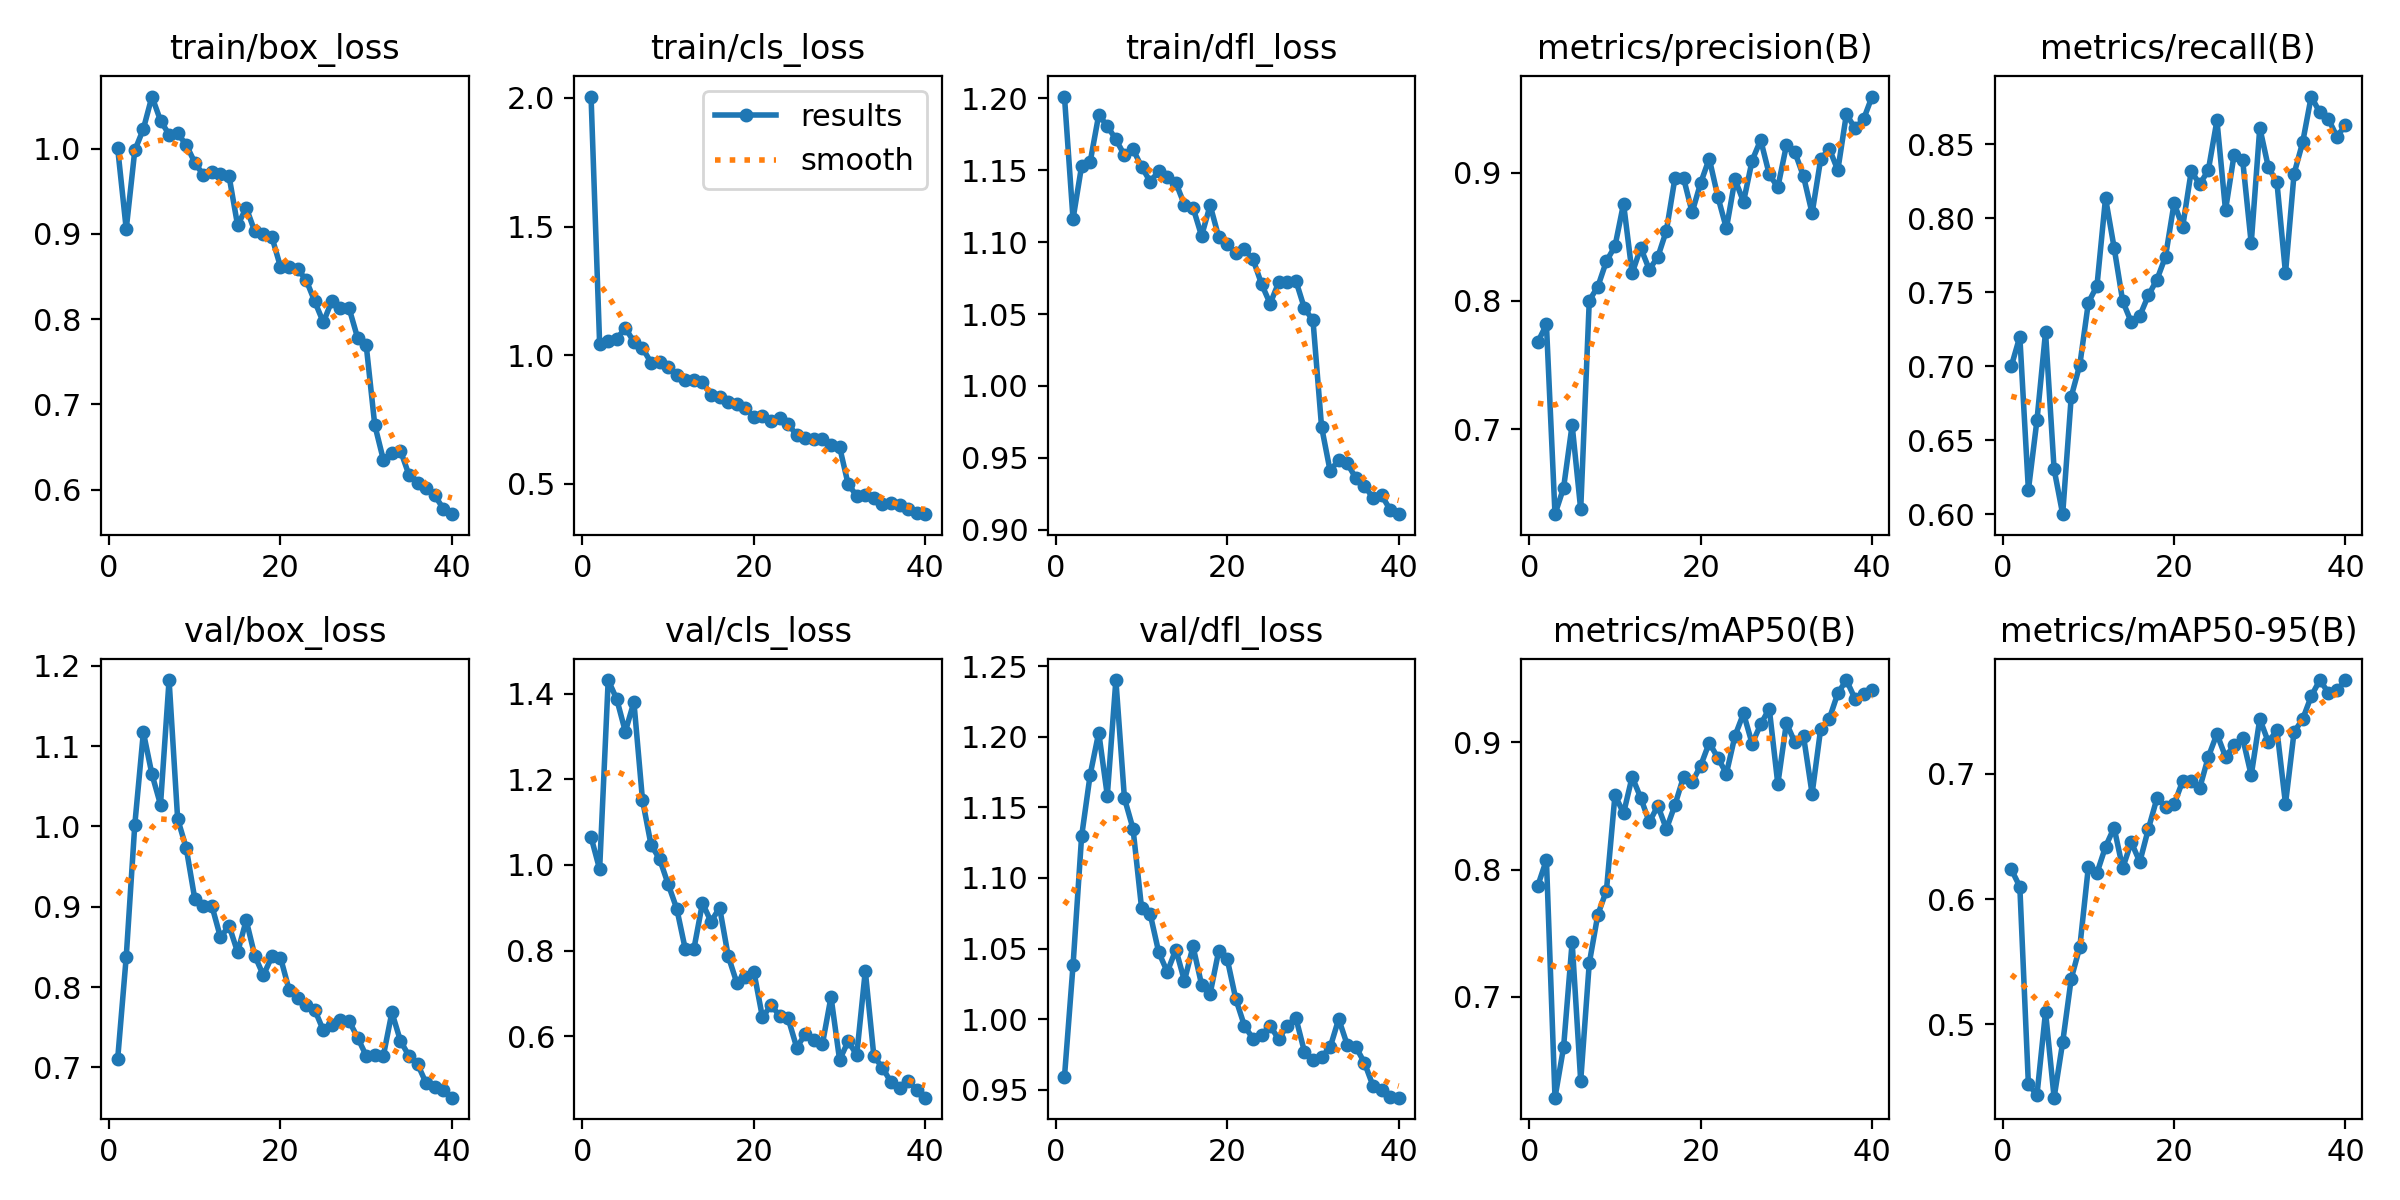

In [9]:
!python scripts/train.py --config configs/exp_imgsz320.yaml
display(Image("runs/exp_imgsz320/results.png", width=1100))

## 4. Compare both runs on the validation set and choose the final run

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1863.0±556.6 MB/s, size: 41.9 KB)
val: Scanning /content/csci1409-object-detection/datasets/african-wildlife-clean/labels/val.cache... 215 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 215/215 41.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 5.4it/s 2.6s
                   all        215        363      0.965      0.882      0.954      0.802
               buffalo         59         86      0.964      0.895      0.944      0.811
              elephant         52         87      0.949      0.851      0.954      0.792
                 rhino         50         79      0.973      0.918      0.965      0.848
                 zebra         58        111      0.972      0.865       0.95      0.7

| Run          | Changed setting   |   Val precision |   Val recall |   Val mAP@0.50 |   Val mAP@0.50:0.95 |   Training time (min) |   Inference (ms/img) |
|:-------------|:------------------|----------------:|-------------:|---------------:|--------------------:|----------------------:|---------------------:|
| baseline     | imgsz = 640       |          0.9646 |       0.8823 |         0.9535 |              0.8025 |                 11.63 |                 3.59 |
| exp_imgsz320 | imgsz = 320       |          0.9449 |       0.8698 |         0.9488 |              0.7738 |                  7.34 |                 2.35 |


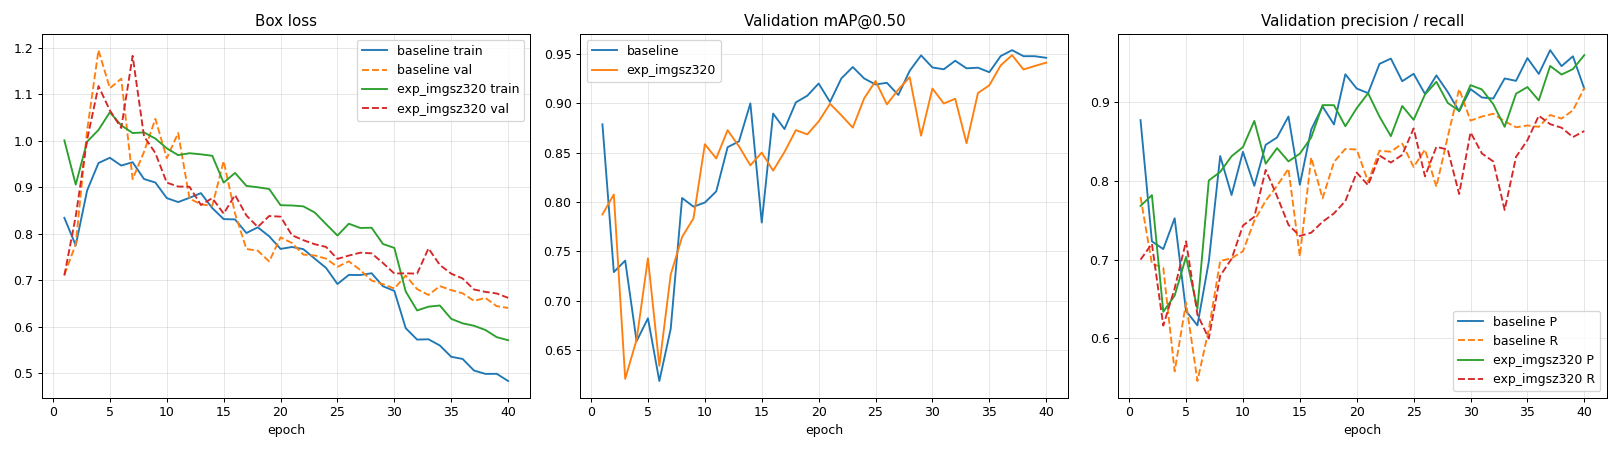

In [10]:
!python scripts/evaluate.py --weights runs/baseline/weights/best.pt --split val --imgsz 640 --name baseline
!python scripts/evaluate.py --weights runs/exp_imgsz320/weights/best.pt --split val --imgsz 320 --name exp_imgsz320
!python scripts/compare_runs.py
display(Markdown(open("results/comparison.md").read()))
display(Image("results/learning_curves_comparison.png", width=1100))

## 5. Final evaluation on the held-out TEST set
The final run is chosen **only** from validation results (`results/final_run.json`). The test set is used once.

In [11]:
final = json.load(open("results/final_run.json")); print(final)
!python scripts/evaluate.py --weights {final["weights"]} --split test --imgsz {final["imgsz"]} --name final

{'final_run': 'baseline', 'imgsz': 640, 'weights': 'runs/baseline/weights/best.pt', 'rule': 'highest validation mAP@0.50 (ties within 0.005 broken by mAP@0.50:0.95)'}
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1744.0±342.9 MB/s, size: 75.3 KB)
val: Scanning /content/csci1409-object-detection/datasets/african-wildlife-clean/labels/test... 205 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 205/205 2.2Kit/s 0.1s
val: New cache created: /content/csci1409-object-detection/datasets/african-wildlife-clean/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 5.0it/s 2.6s
                   all        205        340      0.969      0.917      0.971      0.808
               buffalo         39         51      0.995      0.922      0.967      

{
  "weights": "runs/baseline/weights/best.pt",
  "split": "test",
  "imgsz": 640,
  "conf_threshold": 0.25,
  "nms_iou": 0.7,
  "match_iou": 0.5,
  "TP": 320,
  "wrong_class": 2,
  "poor_box": 5,
  "false_positive": 31,
  "missed": 20,
  "gt": 340,
  "precision_at_conf": 0.8939,
  "recall_at_conf": 0.9412,
  "images_with_any_error": 42
}
Failure candidates: {
  "missed": [
    "2 (130).jpg",
    "2 (97).jpg",
    "4 (138).jpg",
    "4 (116).jpg"
  ],
  "false_positive": [
    "4 (105).jpg",
    "2 (290).jpg",
    "4 (294).jpg",
    "4 (81).jpg"
  ],
  "wrong_class": [
    "3 (55).jpg",
    "3 (8).jpg"
  ],
  "poor_box": [
    "2 (97).jpg",
    "4 (138).jpg",
    "1 (373).jpg",
    "4 (235).jpg"
  ]
}


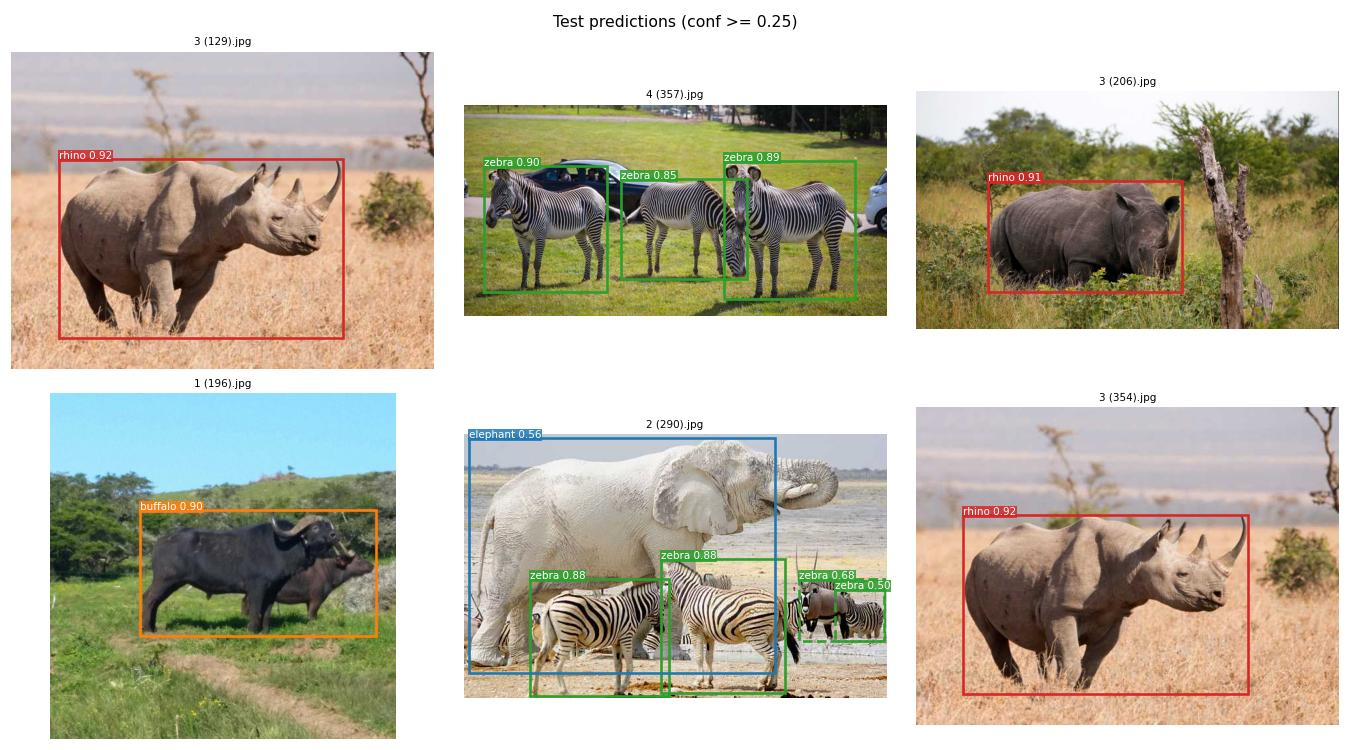

In [12]:
!python scripts/predict_and_failures.py --weights {final["weights"]} --split test --imgsz {final["imgsz"]} --conf 0.25
display(Image("results/test_predictions/predictions_grid.jpg", width=1100))

### Failure type: missed

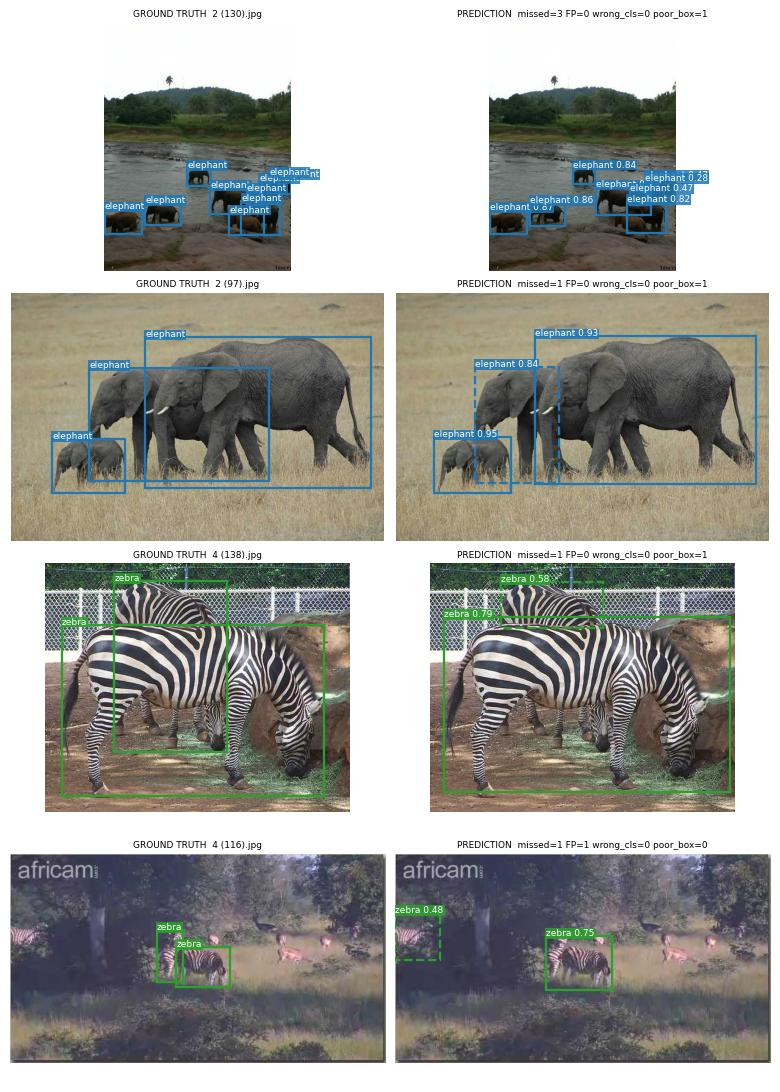

### Failure type: false_positive

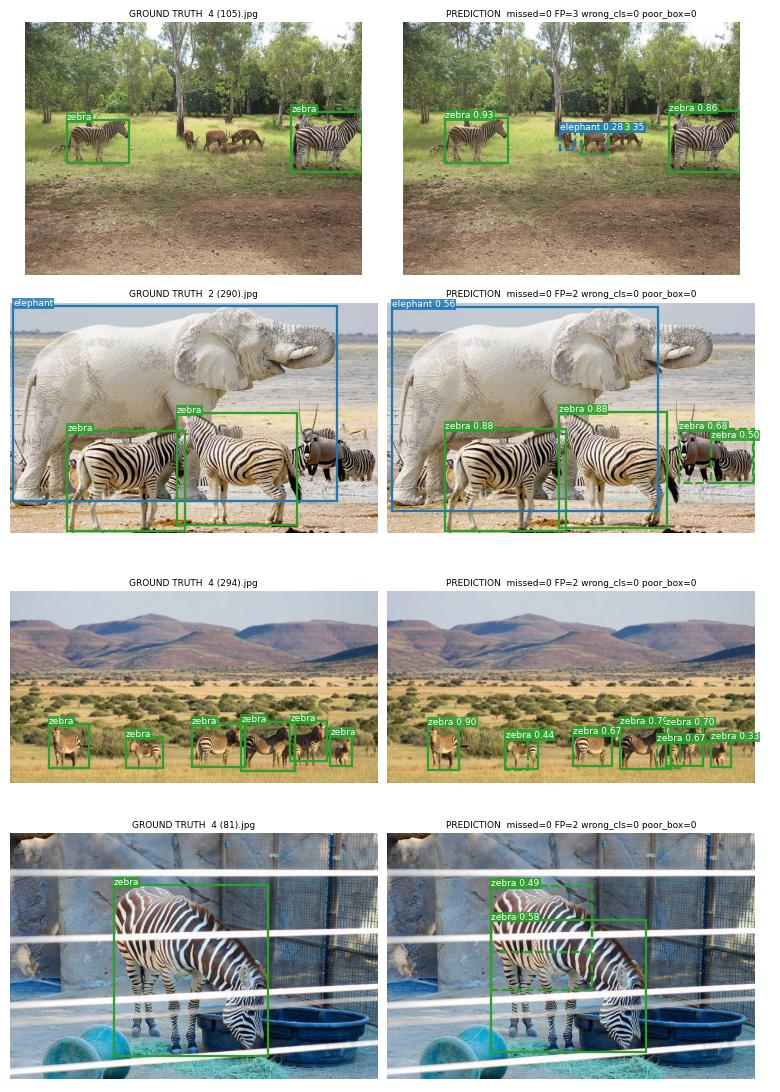

### Failure type: wrong_class

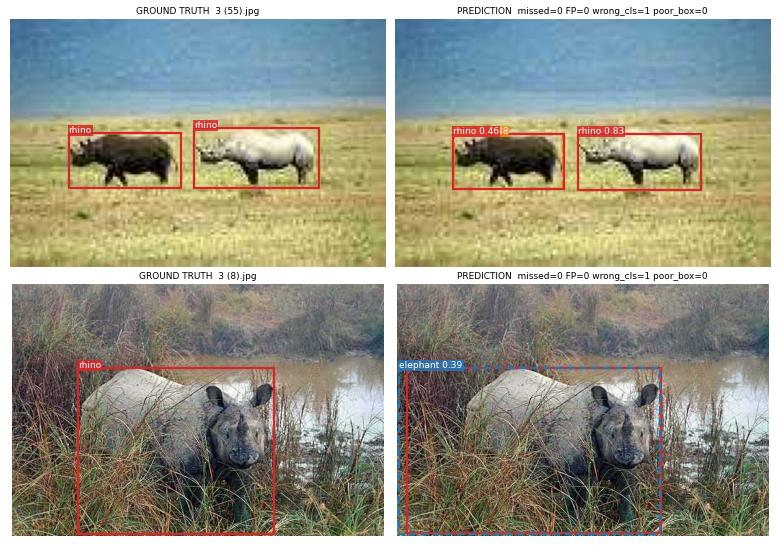

### Failure type: poor_box

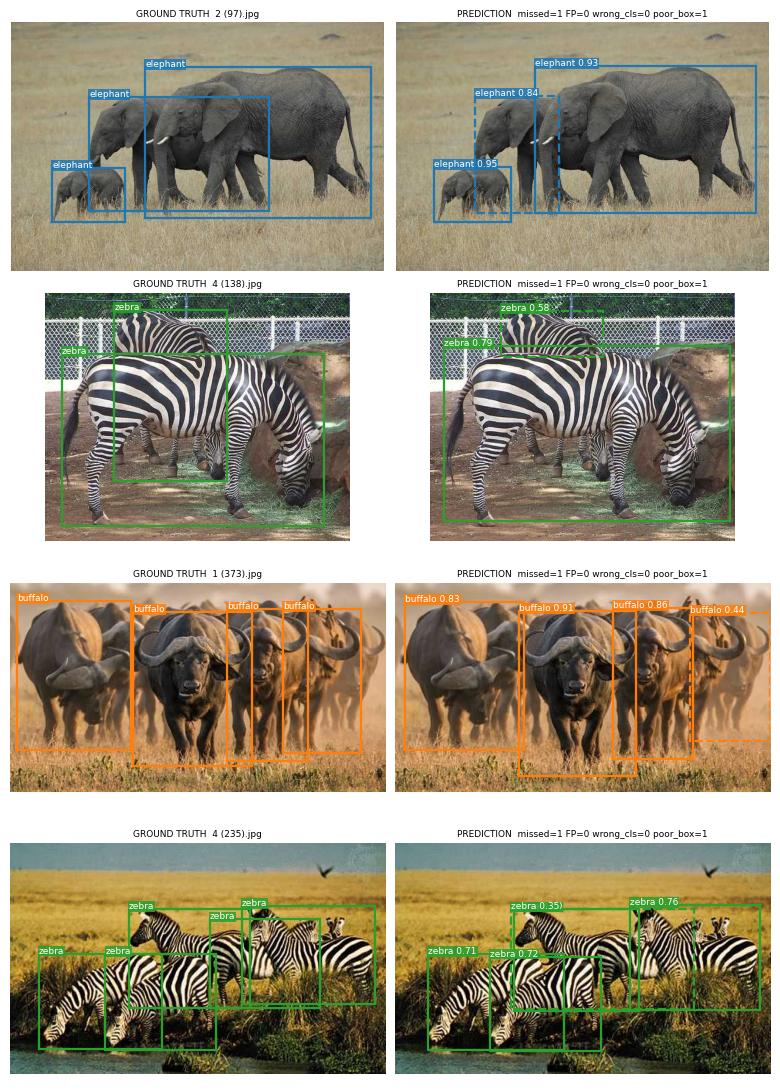

In [13]:
import os
for kind in ["missed", "false_positive", "wrong_class", "poor_box"]:
    p = f"results/test_predictions/failures_{kind}.jpg"
    if os.path.exists(p):
        display(Markdown(f"### Failure type: {kind}")); display(Image(p, width=900))
    else:
        print("No", kind, "failures at conf 0.25")

## 6. Save and download all outputs

In [14]:
!python scripts/collect_outputs.py
from google.colab import files
files.download("outputs.zip")

Final checkpoint -> /content/csci1409-object-detection/weights/best.pt
Wrote /content/csci1409-object-detection/outputs.zip (24.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. (Optional) Use the trained checkpoint without training
Downloads `weights/best.pt` from the repository and predicts on a few test images.

downloaded

0: 640x640 1 buffalo, 5.8ms
1: 640x640 1 buffalo, 5.8ms
2: 640x640 1 buffalo, 5.8ms
Speed: 17.0ms preprocess, 5.8ms inference, 4.7ms postprocess per image at shape (1, 3, 640, 640)


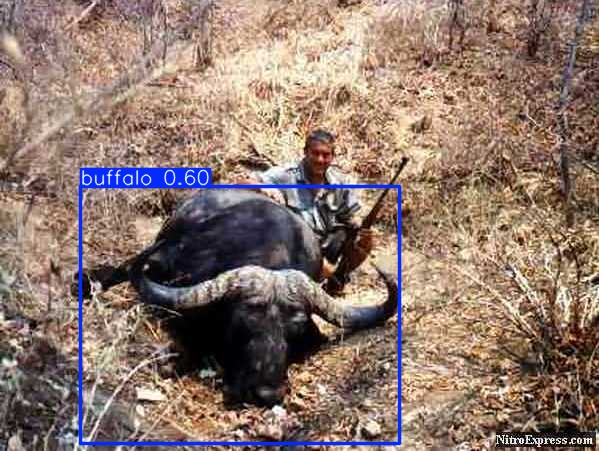

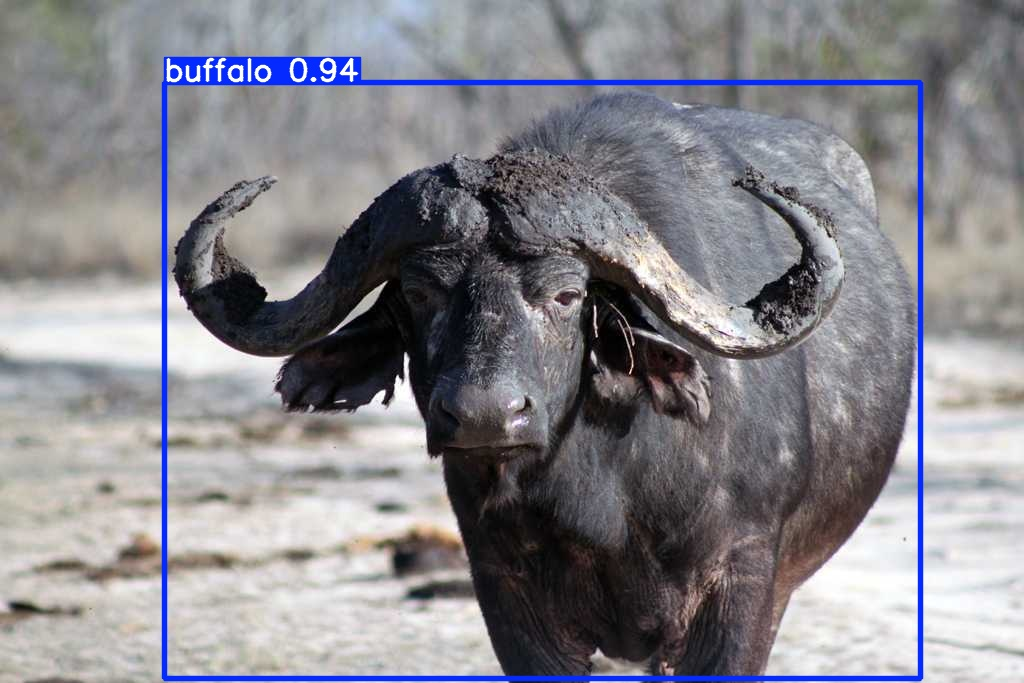

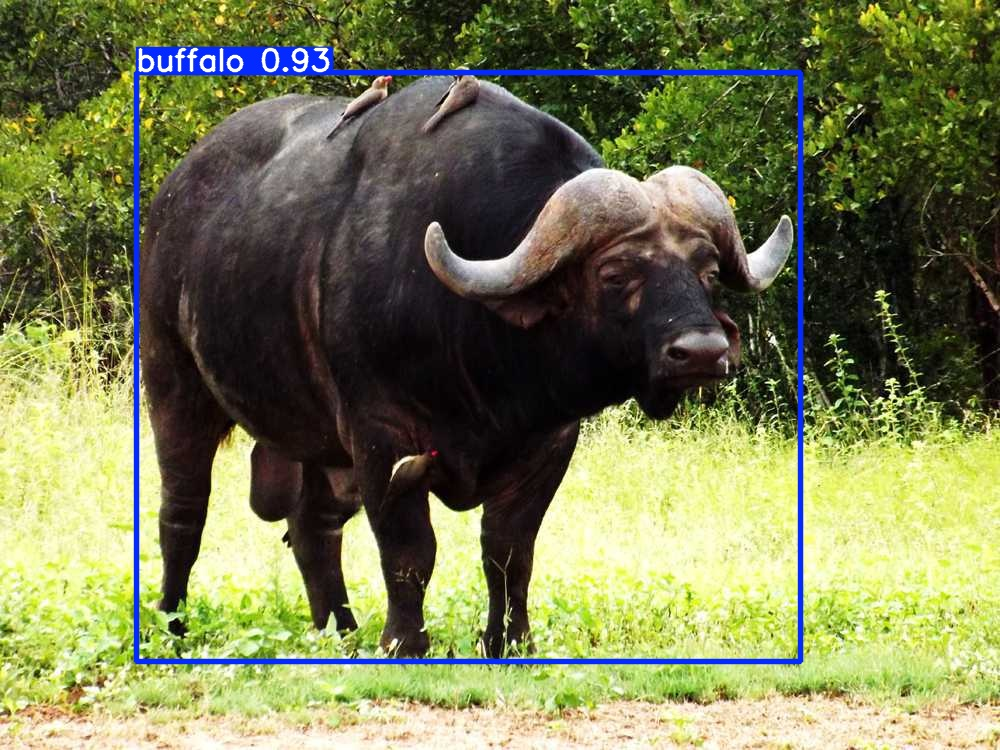

In [15]:
WEIGHTS_URL = REPO_URL.replace(".git", "").replace("github.com", "raw.githubusercontent.com") + "/main/weights/best.pt"
!wget -q -O /content/best_downloaded.pt {WEIGHTS_URL} && echo downloaded
from ultralytics import YOLO
import glob
m = YOLO("/content/best_downloaded.pt")
for r in m.predict(sorted(glob.glob("datasets/african-wildlife-clean/images/test/*"))[:3], conf=0.25):
    display(Image(data=__import__("cv2").imencode(".jpg", r.plot())[1].tobytes(), width=500))